In [1]:
import time, json, warnings
from pathlib import Path
from itertools import combinations
import urllib.request
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import torch
import torch.nn as nn
from scipy.linalg import hankel
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.manifold import TSNE
import kagglehub
from kagglehub import KaggleDatasetAdapter

C:\Users\Admin\AppData\Local\anaconda3\envs\ml-projects\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
warnings.simplefilter("ignore")
plt.rcParams["figure.figsize"] = (12, 4)
sns.set_style("whitegrid")
H_MAX, N_SEG, HORIZONS, SEED = 14, 10, [1, 7, 14], 42

In [3]:
from pathlib import Path

DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

# Загрузка данных

акции Apple

In [4]:
df_apple = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "anukaggle81/usa-top-900-historic-dataset",
    "Apple.csv",
)
df_apple = df_apple.drop(columns=["Unnamed: 0"])
df_apple["Date"] = pd.to_datetime(df_apple["Date"])
df_apple = df_apple.sort_values("Date").reset_index(drop=True)
apple = df_apple["Close"].to_numpy(dtype=float)
print("Apple:", apple.shape)

Apple: (11156,)


MTA Subway Hourly Ridership (NYC)

In [5]:
url = "https://github.com/xinychen/integers/raw/main/Manhattan-subway/NYC_subway_mob_24.npz"
urllib.request.urlretrieve(url, DATA_DIR / "NYC_subway_mob_24.npz")
tensor = np.load(DATA_DIR / "NYC_subway_mob_24.npz")["arr_0"]
hourly_total = tensor.sum(axis=0).astype(float)
dates_sub = pd.date_range("2024-01-01", periods=len(hourly_total), freq="h")
bad = np.where(hourly_total[: 24 * 319] == 0)[0]      # 10 марта 02:00 — переход на летнее время
hourly_total[bad] = (hourly_total[bad - 1] + hourly_total[bad + 1]) / 2
print("Subway:", hourly_total.shape)

Subway: (8784,)


Потребление электроэнергии

In [6]:
energy_path = kagglehub.dataset_download("robikscube/hourly-energy-consumption")
df_energy = pd.read_csv(Path(energy_path) / "PJME_hourly.csv")
df_energy["Datetime"] = pd.to_datetime(df_energy["Datetime"])
df_energy = (df_energy.drop_duplicates(subset="Datetime")
                      .sort_values("Datetime")
                      .set_index("Datetime"))
g = df_energy["PJME_MW"].resample("D")
daily = g.mean()[g.count() >= 23]
energy = daily.to_numpy(dtype=float)
print("Energy:", energy.shape, daily.index[0].date(), "—", daily.index[-1].date())

Energy: (6058,) 2002-01-01 — 2018-08-02


Для анализа фазового пространства возьмем последние 1000 точек каждого ряда: DimEmb перебирает пары точек на чистом Python за O(n^2), а класс Graph рассчитан на ряд не длиннее 1000 точек
* Apple последние 1000 цен закрытия;
* Метро последние 1000 часов до 14 ноября 2024;
* Энергия последние 1000 суток.

In [7]:
FC_SERIES = {"Apple": apple,
             "Subway": hourly_total[: dates_sub.get_loc("2024-10-30 23:00") + 1],
             "Energy": energy}
PH = {"Apple": apple[-1000:],
      "Subway": hourly_total[: 24 * 319][-1000:],
      "Energy": energy[-1000:]}
PHASE_IDX = {"Subway": dates_sub[: 24 * 319][-1000:], "Energy": daily.index[-1000:]}   # даты точек фрагмента

Функции взяла из [github.com/Anthony-Cov/Libraries](https://github.com/Anthony-Cov/Libraries): DimEmb из features.py и класс Graph из graph.py (методы MakeGraph, GraphEntropy, DrawGraph, TransMatr)

Некоторые отличия от оригинала:
1. Norm01 скопирована из Util.py
2. В `Graph.__init__` размерность вложения передается аргументом demb (считаем ее DimEmb)
3. В DrawGrap защита от деления на 0, когда узлов меньше 7

In [8]:
def Norm01(x):
    mi = np.nanmin(x)
    ma = np.nanmax(np.array(x) - mi)
    if ma > 0.:
        x_n = (np.array(x) - mi) / ma
        return x_n, mi, ma
    else:
        return np.zeros(len(x)), mi, ma


'''Размерность вложения по корреляционному интегралу'''
def DimEmb(tser, eps=.1):
    ser, _, _ = Norm01(tser)
    n = len(ser)
    cn = [1]
    d0 = 0
    h = hankel(ser)
    for k in range(2, n // 2):
        ent = sum(cn)
        w = h[:n - k, :k]
        ro = np.zeros([n - k, n - k])
        for i, j in combinations(np.arange(n - k), 2):
            norm = np.linalg.norm(w[i] - w[j])
            ro[i, j] = norm
            ro[j, i] = norm
        cl = []
        cn = []
        ls = np.linspace(ro[ro != 0].min(), ro.max(), num=20)
        for l in ls:
            c = np.heaviside(l - ro - np.diag(np.ones(n - k)), 1).sum() // 2
            cn.append(c / (n - k) ** 2)
            cl.append(np.log(c / (n - k) ** 2))
        dc = (cl[1] - cl[0]) / (np.log(ls[1]) - np.log(ls[0]))
        if abs(dc - d0) > eps:
            d0 = dc
        else:
            break
    k -= 1
    dc = d0
    ent = sum(cn) / ent
    return k, dc, ent  # k - размерность вложения, dc - корреляционная размерность, ent - оценка энтропии


class Graph():
    def __init__(self, row, demb):          # было: demb из EmbDim.so
        self.demb = demb
        self.row = row

    '''Создание графа из ряда'''
    def MakeGraph(self, mindist=.01):
        depth = self.demb * 2 + 1
        self.traject = pd.DataFrame(columns=['step'] + ['t-' + str(j) for j in range(depth - 1, -1, -1)])
        self.traject['step'] = np.arange(len(self.row) - depth)
        for i in range(len(self.row) - depth):
            self.traject.loc[i, self.traject.columns[1:]] = self.row[i:i + depth]
        '''матрица связей для кластеризации'''
        link = linkage(self.traject[self.traject.columns[1:]], 'ward', 'euclidean')
        '''оптимальное расстояние для кластеризации'''
        dist = link[:, 2]
        dist_rev = dist[::-1]
        i = np.where(np.abs(dist_rev[:-5] - dist_rev[5:]) < (max(dist_rev) * mindist))[0][0]
        d = dist_rev[i]
        '''кластеризация'''
        self.traject['cluster'] = fcluster(link, d, criterion='distance')
        self.traject['cluster'] = [list(self.traject['cluster'].drop_duplicates().values).index(i) + 1
                                   for i in self.traject['cluster']]
        '''Граф'''
        nod = self.traject['cluster'].values
        self.G = nx.DiGraph()
        self.G.add_nodes_from(self.traject['cluster'].unique())
        r = [(nod[j], nod[j + 1]) for j in range(len(self.traject) - 1)]
        c = [r.count(i) for i in r]
        self.G.add_weighted_edges_from([(nod[j], nod[j + 1], c[j]) for j in range(len(self.traject) - 1)])
        self.n_nodes = self.G.number_of_nodes()
        return self.G

    '''Расчет энтропии графа'''
    def GraphEntropy(self):
        centrality = nx.degree_centrality(self.G).values()
        centrality = np.asarray(list(centrality))
        centrality /= centrality.sum()
        dist = np.asarray(centrality)
        ent = np.nansum(dist * np.log2(1 / dist))
        return ent

    '''Рисование графа'''
    def DrawGraph(self, title=''):
        matplotlib.style.use('fast')
        fig = plt.figure(figsize=(10, 10))
        plt.title(title, size=20)
        lnd = self.n_nodes + 1
        nnd = max(1, lnd // 7)              # было: lnd // 7
        nlist = [range(i, i + lnd // nnd) for i in range(0, lnd - lnd // nnd, lnd // nnd)] + [range(lnd - lnd // nnd, lnd)]
        nx.draw(self.G, pos=nx.shell_layout(self.G, nlist=nlist),
                with_labels=True,
                node_color='pink', font_weight='bold', font_size=10,
                edge_color='b', node_size=300, width=2)
        fig.tight_layout()
        plt.show()
        return self

    '''Матрица вероятностей переходов'''
    def TransMatr(self, paint=False):
        matplotlib.style.use('fast')
        n_neighbors = self.n_nodes
        adj = dict(self.G.adjacency())
        superficies = np.zeros([n_neighbors, n_neighbors])
        for i in adj.keys():
            if len(adj[i].keys()) == 0:
                continue
            for j in adj.keys():
                if i == j:
                    if j in adj[i].keys():
                        s = sum([adj[i][k]['weight'] for k in adj[i].keys()])
                        superficies[i - 1, j - 1] = adj[i][j]['weight'] / s if s > 0. else 0.
                else:
                    probab = 0
                    for path in nx.algorithms.simple_paths.all_simple_paths(self.G, i, j):
                        p = 1
                        for n in range(len(path) - 1):
                            s = sum([adj[path[n]][k]['weight'] for k in adj[path[n]].keys()])
                            if s > 0.:
                                p *= adj[path[n]][path[n + 1]]['weight'] / s
                                if p < .001: break
                            else:
                                p = 0.
                                break
                        probab += p
                    superficies[i - 1, j - 1] = probab
            superficies[i - 1, :] = superficies[i - 1, :] / superficies[i - 1, :].sum()
        if paint:
            fig, ax = plt.subplots(figsize=(10, 10))
            fig.patch.set_facecolor('white')
            im = ax.imshow(superficies[::-1], interpolation='none')
            cbar = ax.figure.colorbar(im, ax=ax, shrink=.75)
            cbar.ax.set_ylabel('Probability (%)', va="top", size=16)
            cbar.set_ticks(np.linspace(superficies.min(), superficies.max(), 10))
            cbar.set_ticklabels(np.linspace(superficies.min() * 100, superficies.max() * 100, 10).astype(int))
            ax.set_xticks(np.arange(n_neighbors))
            ax.set_yticks(np.arange(n_neighbors))
            ax.set_xlabel('To node', size=16)
            ax.set_ylabel('From node', size=16)
            ax.set_facecolor('white')
            for i in range(n_neighbors):
                for j in range(n_neighbors):
                    ax.text(j, i, (100 * superficies[n_neighbors - i - 1, j]).round(2),
                            ha="center", va="center", color="w", size=12)
            ax.grid()
            ax.set_xticklabels((np.arange(n_neighbors) + 1).astype(str))
            ax.set_yticklabels((n_neighbors - np.arange(n_neighbors)).astype(str))
            ax.set_title("Transition probability between graph nodes", size=20)
            fig.tight_layout()
            plt.show()
        return superficies

# 1. Корреляционная размерность и размерность вложения

Чтобы понять, как DimEmb отражает известные свойства рядов, ИИ дал реализацию запуска на эталонах: 5 реализаций случайного блуждания и синус (истинная D2 = 1) без шума и с шумом 5%

In [9]:
rng = np.random.default_rng(SEED)
t = np.arange(1000)
ref = {f"блуждание {s}": np.cumsum(np.random.default_rng(s).standard_normal(1000)) for s in range(1, 6)}
ref["синус без шума (D2 = 1)"] = np.sin(2 * np.pi * t / 24)
ref["синус + 5 % шума (D2 = 1)"] = np.sin(2 * np.pi * t / 24) + 0.05 * rng.standard_normal(1000)
ref_tbl = pd.DataFrame([dict(zip(["E", "D2", "энтропия"], DimEmb(x)), ряд=k) for k, x in ref.items()]).set_index("ряд")
display(ref_tbl.round(3))

,E,D2,энтропия
ряд,,,
блуждание 1,7,4.141,0.999
блуждание 2,11,5.903,0.997
блуждание 3,5,3.620,0.997
блуждание 4,7,4.631,0.999
блуждание 5,12,6.713,0.998
синус без шума (D2 = 1),2,0.171,0.986
синус + 5 % шума (D2 = 1),5,3.677,0.963


In [10]:
EMB, DIM = {}, []
for name, x in PH.items():
    t0 = time.perf_counter()
    k, dc, ent = DimEmb(x)
    EMB[name] = k
    DIM.append({"ряд": name, "E (размерность вложения)": k, "D2 (корреляционная размерность)": round(dc, 2),
                "корреляционная энтропия": round(ent, 3), "глубина окна 2E+1": 2 * k + 1,
                "время, с": round(time.perf_counter() - t0, 1)})
dim_table = pd.DataFrame(DIM).set_index("ряд")
display(dim_table)

,E (размерность вложения),D2 (корреляционная размерность),корреляционная энтропия,глубина окна 2E+1,"время, с"
ряд,,,,,
Apple,9,4.31,0.997,19,10.4
Subway,5,2.04,0.954,11,5.7
Energy,9,5.63,0.992,19,10.4


* **Apple:** E = 9, D2 = 4.31. Для сравнения DimEmb запущена на 5 реализациях чистого случайного блуждания той же длины: E = 5-12, D2 = 3.6-6.7. Apple попадает в этот диапазон, то есть по этим оценкам ряд неотличим от блуждания. Конечная D2 здесь не означает аттрактора
* **Метро:** E = 5, D2 = 2.04 - самые низкие значения из трех рядов и вне диапазона случайного блуждания. Абсолютное значение D2 у DimEmb ненадежно: для синуса (истинная D2 = 1) она дает 0.17 без шума и 3.68 при шуме 5%, так как наклон берется на самых малых масштабах, где доминирует шум. Поэтому D2 используем только для сравнения рядов между собой
* **Энергия:** E = 9, D2 = 5.63 - в диапазоне случайного блуждания и близко к пределу надежности D2 = 2·log₁₀N ≈ 6 для N = 1000. Низкоразмерную динамику по этим оценкам обнаружить нельзя. Вероятная причина в том, что погода как внешний случайный фактор (это предположение)
* Корреляционная энтропия у всех рядов близка к 1, но у блуждания 0.997–0.999, у синуса 0.963–0.986. Метро (0.954) ближе всего к периодическому сигналу, Apple (0.997) к блужданию, энергия (0.992) между ними

# 2. Фазовая траектория и t-SNE

Фазовую траекторию взяа ту же, что использует Graph.MakeGraph: векторы из 2E+1 подряд идущих отсчетов (оценка достаточной размерности по Такенсу). Сжимаем их t-SNE до 2D (perplexity 30, инициализация PCA). Соседние по времени точки соединены линией, цвет - это фаза - для метро час недели, для энергии день года, для Apple номер дня

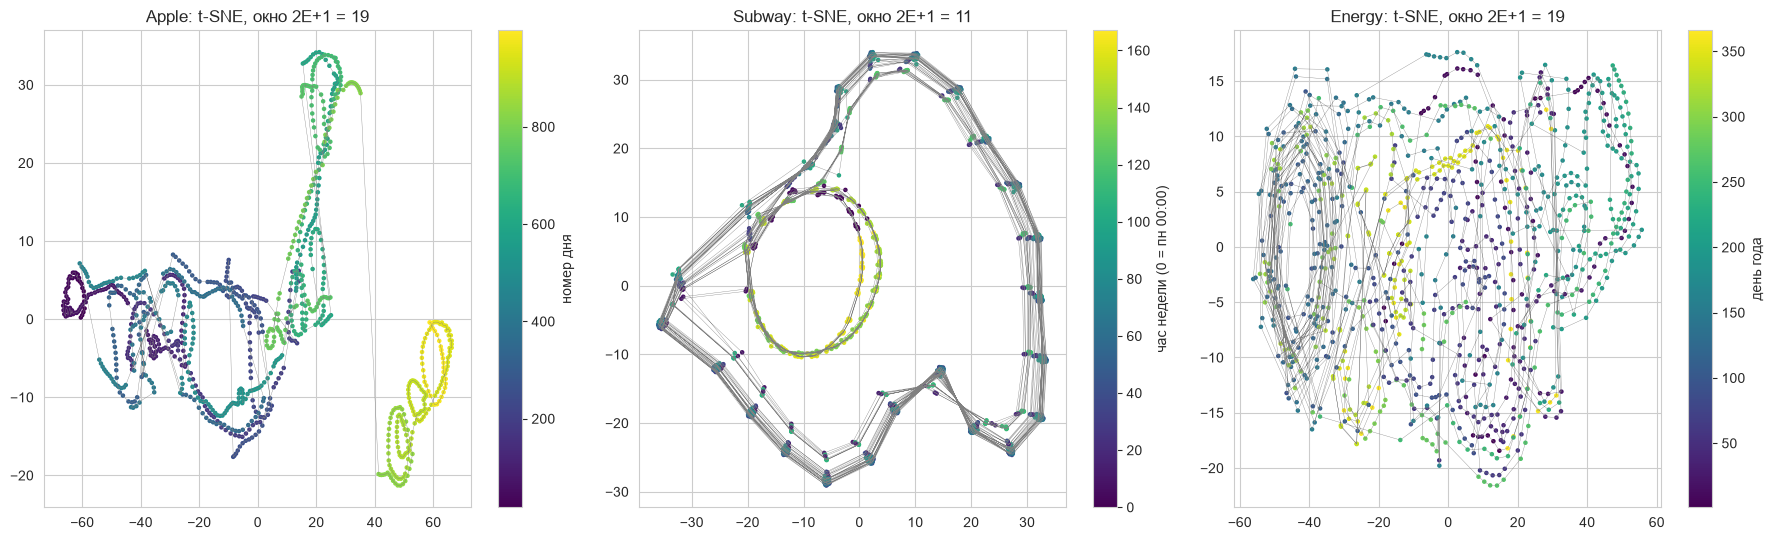

In [11]:
GR, TSNE2, PHASE = {}, {}, {}
for name, x in PH.items():
    g = Graph(x, EMB[name])
    g.MakeGraph()
    GR[name] = g
    V = g.traject[g.traject.columns[1:-1]].to_numpy(float)
    TSNE2[name] = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(V)
    depth = 2 * EMB[name] + 1
    end = np.arange(len(V)) + depth - 1
    if name == "Subway":
        PHASE[name] = (PHASE_IDX[name].dayofweek * 24 + PHASE_IDX[name].hour).to_numpy()[end]
    elif name == "Energy":
        PHASE[name] = PHASE_IDX[name].dayofyear.to_numpy()[end]
    else:
        PHASE[name] = end

clabel = {"Apple": "номер дня", "Subway": "час недели (0 = пн 00:00)", "Energy": "день года"}
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, name in zip(axes, PH):
    Y = TSNE2[name]
    ax.plot(Y[:, 0], Y[:, 1], lw=0.25, color="gray")
    sc = ax.scatter(Y[:, 0], Y[:, 1], c=PHASE[name], s=5, cmap="viridis")
    plt.colorbar(sc, ax=ax, label=clabel[name])
    ax.set_title(f"{name}: t-SNE, окно 2E+1 = {2 * EMB[name] + 1}")
plt.tight_layout(); plt.show()

* Apple

Непрерывная нить, цвет вдоль нее меняется монотонно. Траектория не возвращается в пройденные области, а последние примерно 150 дней лежат отдельным островом (новый уровень цены). Это блуждание, а не аттрактор

* Метро

Видны два устойчивых замкнутых кольца. Внешнее - будни (час недели 0–119), внутреннее - выходные (120–167). Витки разных недель ложатся друг на друга, то есть это предельный цикл с суточным периодом, двух режимов

* Энергия

Петли нет, получается облако с сезонным градиентом: начало года слева, лето (200й день) справа. Соседние дни соединены хаотичными скачками (погодный шум поверх годового цикла)

# 3. LSTM с учетом размерности вложения

Базовая модель LSTM из работы 4 с теми же гиперпараметрами, на вход окно из L подряд идущих значений (L = 20 / 168 / 56). С учетом размерности вложения длина окна задается по DimEmb (векторы с τ = 1):
* LSTM (окно E) - ровно вектор вложения из E последних значений
* LSTM (окно 2E+1) - окно глубиной 2E+1, как траектория в Graph.MakeGraph

Все варианты обучаются на одном наборе обучающих моментов, тестовые блоки и валидация те же, что в работе 4 (горизонты 1, 7, 14, 10 непересекающихся блоков, MAPE)

In [12]:
LOOKBACK = {"Apple": 20, "Subway": 168, "Energy": 56}


def test_origins(n, n_seg=N_SEG, h=H_MAX, gap=H_MAX):
    return [n - h - gap * (n_seg - 1 - k) for k in range(n_seg)]


ORIGINS = {name: test_origins(len(x)) for name, x in FC_SERIES.items()}

try:
    HP = {k: v for k, v in json.load(open(RESULTS_DIR / "lab4_best_hparams.json")).items() if k.endswith("|LSTM")}
except FileNotFoundError:
    HP = {}
    print("lab4_best_hparams.json не найден, n = 64, lr = 1e-3")

def hp_for(name):
    return HP.get(f"{name}|LSTM", dict(hidden=64, lr=1e-3))


def mape(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    return np.mean(np.abs((y - yhat) / y)) * 100


class LSTMNet(nn.Module):
    def __init__(self, n_feat, n_out, hidden):
        super().__init__()
        self.lstm = nn.LSTM(n_feat, hidden, batch_first=True)
        self.head = nn.Linear(hidden, n_out)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1])


def fit_net(model, Xtr, Ytr, Xva, Yva, lr, max_epochs=300, patience=15, batch=64, per_epoch=2048, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    Xtr, Ytr, Xva, Yva = map(torch.from_numpy, (Xtr, Ytr, Xva, Yva))
    best, best_state, wait, n_ep = np.inf, None, 0, 0
    for ep in range(max_epochs):
        model.train()
        idx = torch.randperm(len(Xtr), generator=g)[:per_epoch]
        for b in range(0, len(idx), batch):
            j = idx[b:b + batch]
            loss = loss_fn(model(Xtr[j]), Ytr[j])
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        model.eval()
        with torch.no_grad():
            va = loss_fn(model(Xva), Yva).item()
        n_ep += 1
        if va < best - 1e-6:
            best, wait = va, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    return best, n_ep

Вход для момента i (прогноз начинается с z[i]) - окно из w последних значений лог-ряда. Нормировка как в работе 4: вычитаем последнее наблюдение z[i−1] и делим на СКО изменения за 14 шагов

In [13]:
rows, tim = [], []
for name, x in FC_SERIES.items():
    z = np.log(x)
    E, o0 = EMB[name], ORIGINS[name][0]
    windows = {"LSTM (окно L, заново)": LOOKBACK[name], "LSTM (окно E)": E, "LSTM (окно 2E+1)": 2 * E + 1}
    scale = np.std(z[H_MAX:o0] - z[:o0 - H_MAX])
    hp = hp_for(name)
    idx = np.arange(max(windows.values()), o0 - H_MAX + 1)          # общий набор обучающих моментов
    Y = np.stack([(z[i:i + H_MAX] - z[i - 1]) / scale for i in idx]).astype(np.float32)
    n_va = int(0.15 * len(idx))
    for v, w in windows.items():
        make = lambda i: ((z[i - w:i] - z[i - 1]) / scale)[:, None].astype(np.float32)
        X = np.stack([make(i) for i in idx])
        torch.manual_seed(SEED)
        model = LSTMNet(1, H_MAX, hp["hidden"])
        t0 = time.perf_counter()
        va, n_ep = fit_net(model, X[:-n_va], Y[:-n_va], X[-n_va:], Y[-n_va:], hp["lr"])
        t_fit = time.perf_counter() - t0
        model.eval()
        for k, o in enumerate(ORIGINS[name]):
            with torch.no_grad():
                yhat = np.exp(model(torch.from_numpy(make(o))[None]).numpy()[0] * scale + z[o - 1])
            for h in HORIZONS:
                rows.append(dict(series=name, model=v, horizon=h, segment=k, MAPE=mape(x[o:o + h], yhat[:h])))
        tim.append(dict(series=name, model=v, window=w, val_mse=va, epochs=n_ep, fit_s=t_fit))
res = pd.DataFrame(rows)
tim = pd.DataFrame(tim).set_index(["series", "model"])
VARIANTS = list(windows)

try:
    r4 = pd.read_csv(RESULTS_DIR / "lab4_results.csv")
    r4 = r4[r4.model == "LSTM"].assign(model="LSTM, итог работы 4")[["series", "model", "horizon", "segment", "MAPE"]]
    res = pd.concat([r4, res], ignore_index=True)
    VARIANTS = ["LSTM, итог работы 4"] + VARIANTS
except FileNotFoundError:
    print("lab4_results.csv не найден, сравнение только с переобученной базовой LSTM")

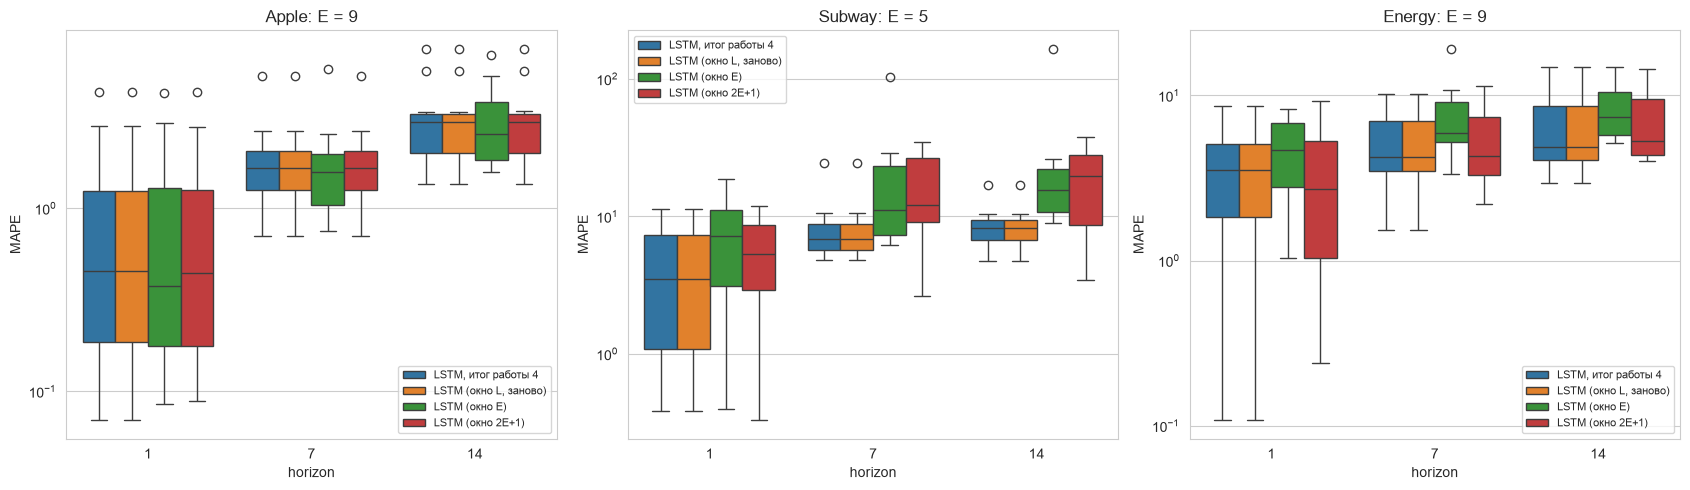

In [14]:
tbl = res.groupby(["series", "horizon", "model"])["MAPE"].median().unstack("model")[VARIANTS]
display(tbl.style.format("{:.2f}").highlight_min(axis=1, color="#c6efce")
        .set_caption("Медиана MAPE, % по 10 блокам"))
display(tim.style.format({"val_mse": "{:.4f}", "fit_s": "{:.1f}"}).set_caption("Окно, валидация и время обучения"))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, name in zip(axes, FC_SERIES):
    sns.boxplot(data=res[res.series == name], x="horizon", y="MAPE", hue="model", hue_order=VARIANTS, ax=ax)
    ax.legend(fontsize=8); ax.set_yscale("log")
    ax.set_title(f"{name}: E = {EMB[name]}")
plt.tight_layout(); plt.show()

* Метро

Окно L = 168 часов лучшее на всех горизонтах (MAPE 3.5 / 6.9 / 8.2%). Окно E = 5 дает 7.2 / 11.1 / 15.5%, а окно 2E+1 = 11 — 5.4 / 12.2 / 19.8%. Окна E и 2E+1 короче суток и не видят ни суточного, ни недельного цикла
* Энергия

на h = 1 окно 2E+1 = 19 лучше базового (2.69 против 3.53%). На h = 7 и 14 выигрывает окно 56 суток (4.25 / 4.85 против 4.32 / 5.26%). Окно E = 9 хуже всех

* Apple

Окно E = 9 формально лучшее (0.38 / 1.57 / 2.56 против 0.46 / 1.66 / 2.97%). Но val_mse почти одинаковый (0.225 против 0.224), а блоков 10 и seed один, так что разница в пределах случайности

Переобученная базовая LSTM (окно L) совпала с итогом работы 4 по всем MAPE: обучение воспроизводимо, поэтому разница между вариантами объясняется только длиной окна

Вывод: окно длиной E или 2E+1 из DimEmb (τ = 1) заметно лучше исходного окна только в одном случае (энергия, h = 1). Для рядов с длинной сезонностью окно должно покрывать период

# 4. Кластеризация фазовых траекторий и граф переходов

Кластеризация уже выполнена в Graph.MakeGraph: векторы траектории разбиваются иерархически методом Уорда, порог отсечения дерева - первое расстояние слияния, после которого расстояния через 5 слияний отличаются меньше чем на 1% от максимального. Каждый кластер - узел графа, ребро i -> j с весом, равным числу переходов траектории из кластера i в j за один шаг

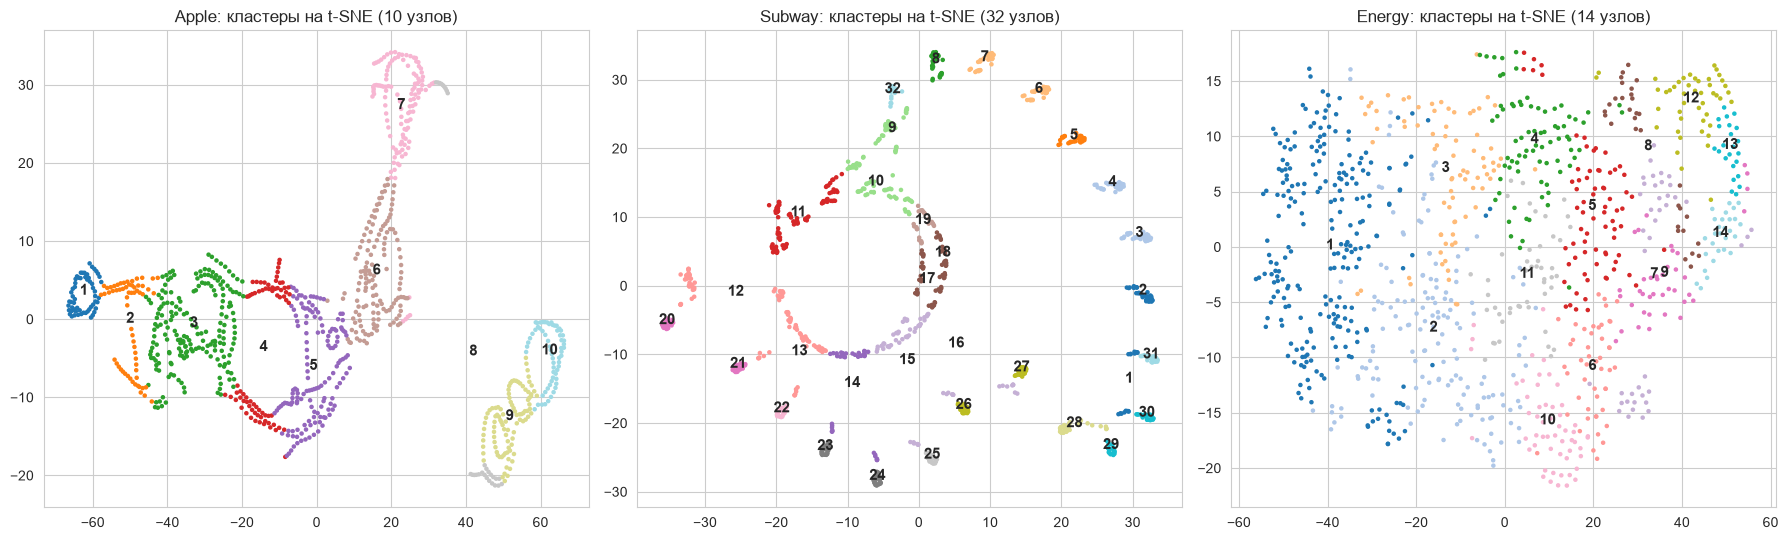

,узлов,рёбер,"энтропия графа, бит","макс. энтропия log2(k), бит"
Apple,10.0,27.0,3.305,3.322
Subway,32.0,53.0,4.844,5.000
Energy,14.0,58.0,3.789,3.807


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, name in zip(axes, PH):
    Y, lab = TSNE2[name], GR[name].traject["cluster"].to_numpy()
    sc = ax.scatter(Y[:, 0], Y[:, 1], c=lab, cmap="tab20", s=5)
    for c in np.unique(lab):
        ax.annotate(str(c), Y[lab == c].mean(0), fontsize=11, fontweight="bold", ha="center")
    ax.set_title(f"{name}: кластеры на t-SNE ({GR[name].n_nodes} узлов)")
plt.tight_layout(); plt.show()

gstats = pd.DataFrame({name: {"узлов": g.n_nodes, "рёбер": g.G.number_of_edges(),
                              "энтропия графа, бит": round(g.GraphEntropy(), 3),
                              "макс. энтропия log2(k), бит": round(np.log2(g.n_nodes), 3)}
                       for name, g in GR.items()}).T
display(gstats)

* Apple. 10 кластеров в последовательных участках одной нити, то есть интервалы времени и уровни цены. Узлы 8-10 лежат отдельным островом, и система туда больше не возвращается
* Метро. 32 компактных кластера, расставленных вдоль двух колец. Каждый кластер определяет фазу суток. Точки разных недель попадают в один и тот же кластер, потому что состояния повторяются. Поэтому кластеры плотные, а переходы между ними почти детерминированные
* Энергия. 14 крупных кластеров с размытыми границами, цвета перемешаны. Устойчивых дискретных состояний нет, разбиение облака на кластеры во многом условное. Слева и справа кластеры примерно соответствуют зиме и лету

**Статистика графа** На один узел приходится разное число ребер, включая петли: у метро 53/32=1.7, у Apple 27/10=2.7, у энергии 58/14=4.1. У метро из каждого состояния почти один выход, это детерминированный цикл. У энергии из одного состояния система уходит во многие, это стохастическая динамика. Энтропия графа у всех рядов близка к максимуму log₂ k и ряды почти не различает, а отношение ребер к узлам различает

Матрица переходов плохо читалась (фиксированные размеры подписей...), поэтому добавлена своя отрисовка: слева матрица за один шаг по весам ребер, справа TransMatr. Нули не закрашиваются, подписи ставятся только у значимых ячеек

In [16]:
def trans_heatmap(ax, M, title, annot_min=None, vmax=None, cmap="rocket_r"):
    n = len(M)
    labels = np.arange(1, n + 1)
    if annot_min is None:
        annot_min = 1 if n <= 15 else 10          # < 1% не подписываем, чтобы не было «0»
    annot = np.where((M * 100 >= annot_min) & (M > 0), np.char.mod("%.0f", M * 100), "")
    sns.heatmap(M * 100, mask=(M == 0), ax=ax, cmap=cmap, vmin=0, vmax=vmax,
                annot=annot, fmt="", annot_kws={"size": 8 if n > 15 else 10},
                square=True, linewidths=0.4, linecolor="0.9",
                xticklabels=labels, yticklabels=labels,
                cbar_kws={"label": "вероятность, %", "shrink": 0.7})
    ax.set_facecolor("white")
    ax.set_xlabel("в узел"); ax.set_ylabel("из узла")
    ax.tick_params(axis="both", labelsize=8 if n > 15 else 10, rotation=0)
    ax.set_title(title)


def show_transitions(name, g):
    n = g.n_nodes
    W = nx.to_numpy_array(g.G, nodelist=range(1, n + 1), weight="weight")   # число переходов i → j
    out = W.sum(1, keepdims=True)
    P1 = np.divide(W, out, out=np.zeros_like(W), where=out > 0)            # вероятность за 1 шаг
    Pall = g.TransMatr(paint=False)                                         # матрица преподавателя
    size = 7 if n <= 15 else 9
    with sns.axes_style("white"):                                           # без сетки whitegrid
        fig, axes = plt.subplots(1, 2, figsize=(2 * size + 2, size))
        trans_heatmap(axes[0], P1, f"{name}: переход за 1 шаг", vmax=100)
        trans_heatmap(axes[1], Pall, f"{name}: TransMatr (по всем простым путям)", cmap="mako_r")
        plt.tight_layout(); plt.show()
    return P1, Pall

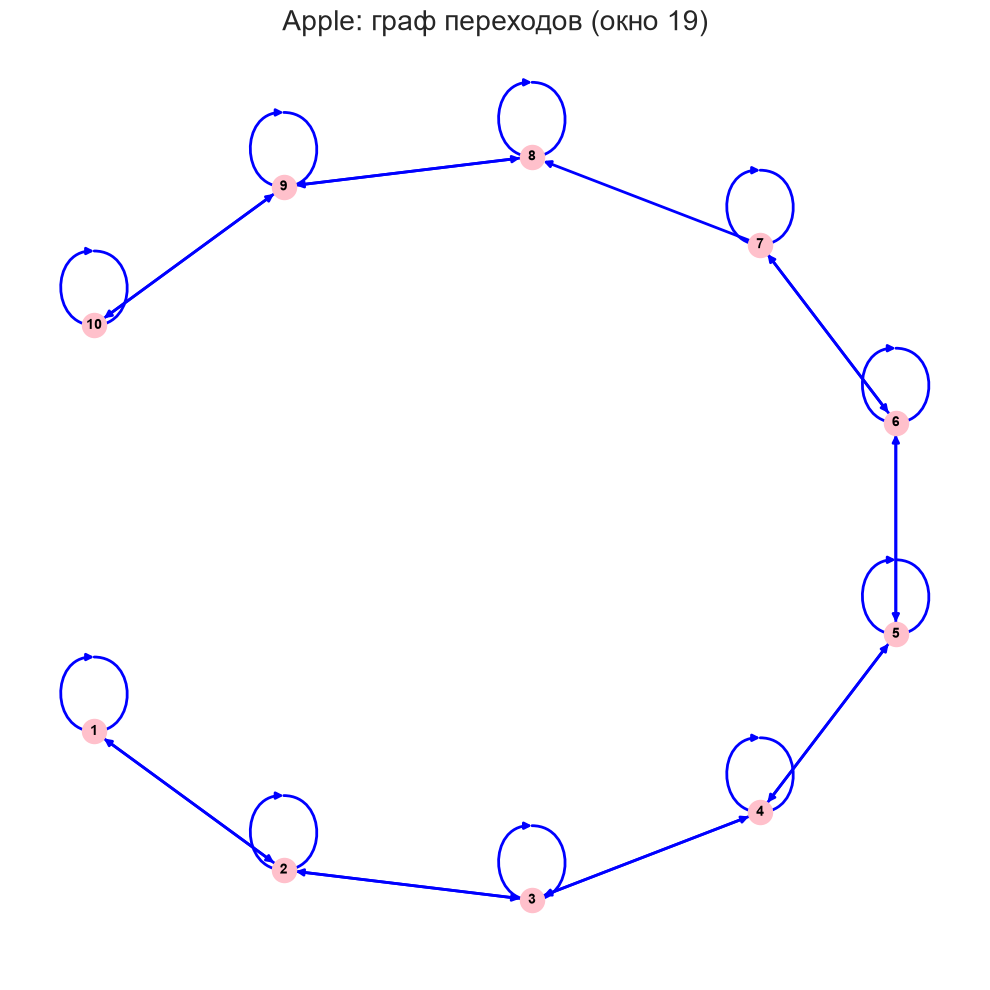

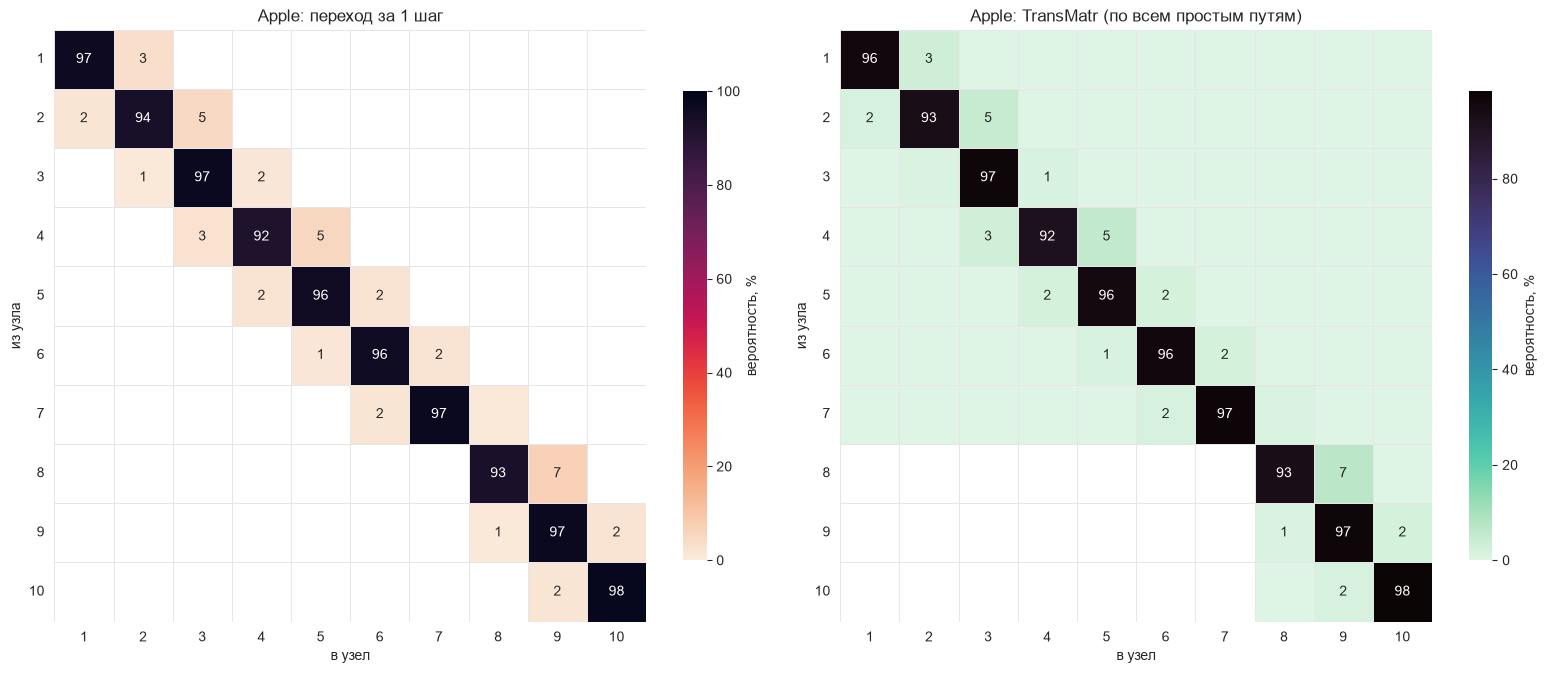

In [17]:
name = "Apple"
GR[name].DrawGraph(f"{name}: граф переходов (окно {2 * EMB[name] + 1})")
P1, Pall = show_transitions(name, GR[name])

10 узлов, по сути это диапазоны уровня цены, то есть граф описывает конкретную траекторию блуждания, на другом отрезке ряда узлы и переходы будут другими

На диагонали 92-98%, остальные переходы только в соседние узлы. Цена долго остается в одном диапазоне и смещается к соседнему, как при блуждании

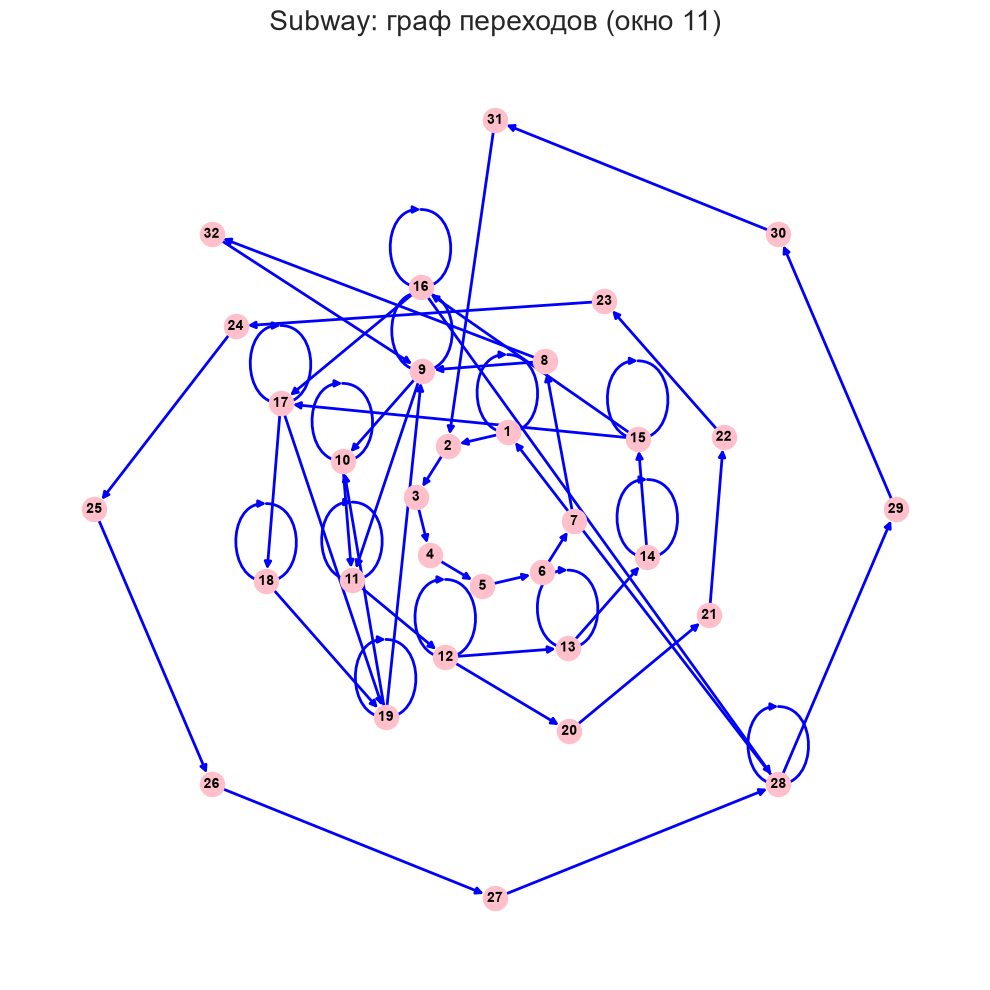

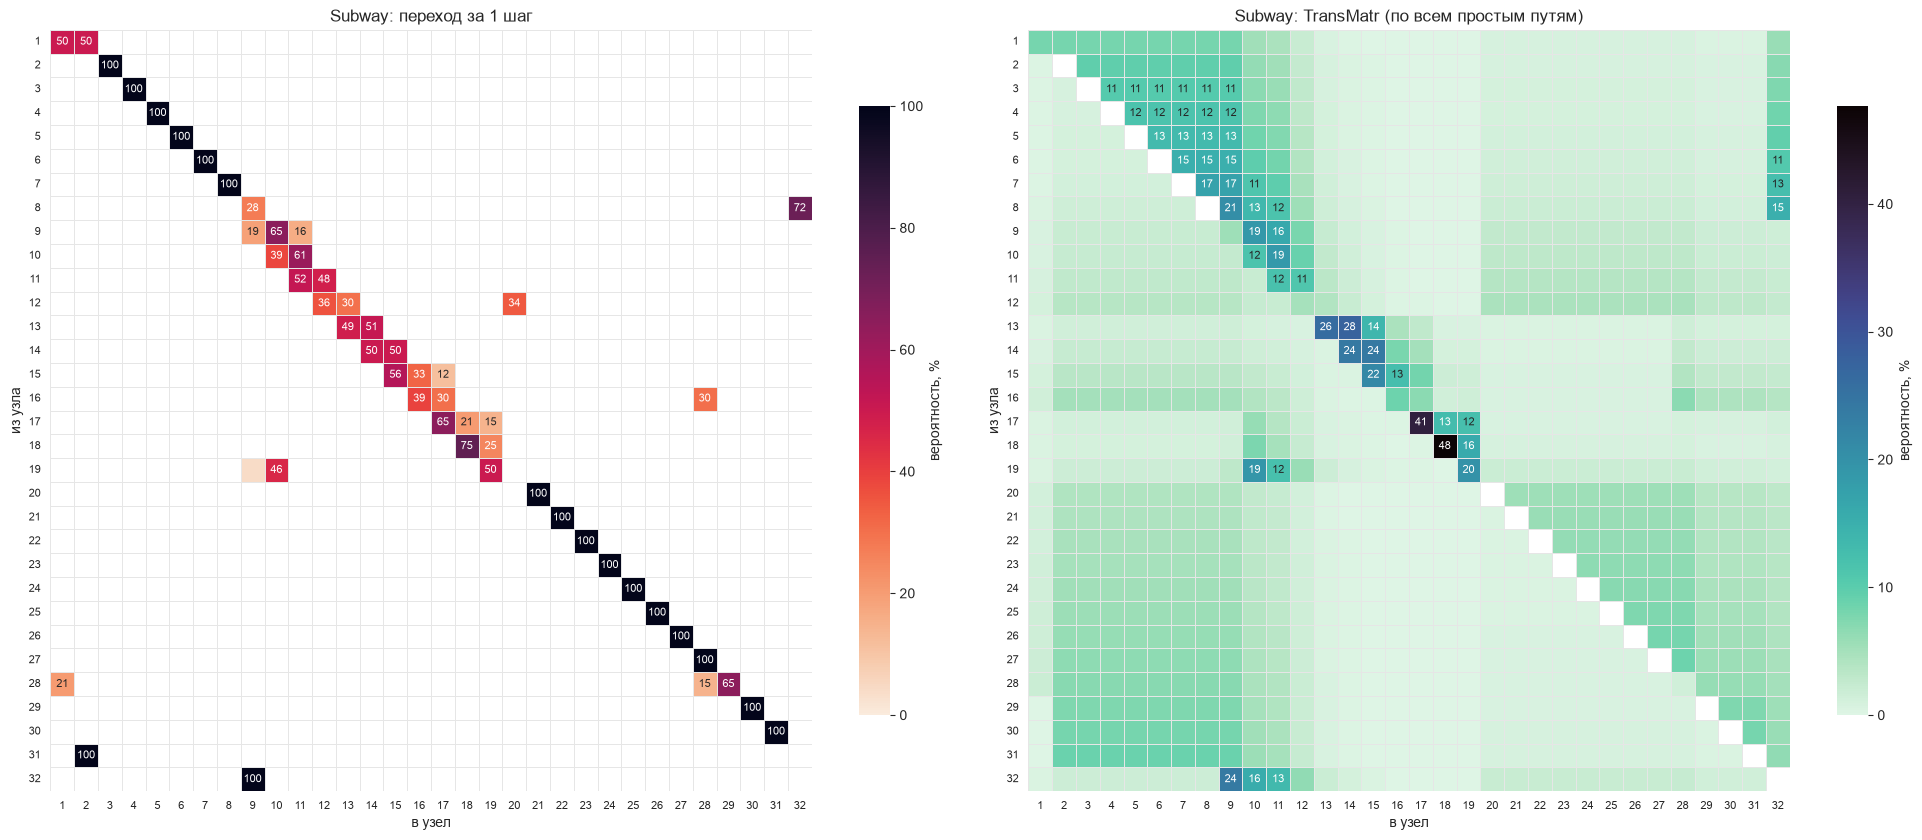

In [18]:
name = "Subway"
GR[name].DrawGraph(f"{name}: граф переходов (окно {2 * EMB[name] + 1})")
P1, Pall = show_transitions(name, GR[name])

32 узла и 53 ребра. Видны суточные циклы, но много узлов с единственным выходом (длинные цепочки): при τ = 1 и окне 11 ч соседние векторы почти совпадают, и иерархическое отсечение дробит цикл на мелкие участки

Длинные цепочки с вероятностью 100 % (2 -> 3 -> … -> 8, 20 -> … -> 28, 29 -> 30 -> 31 -> 2, 32 -> 9), то есть детерминированные участки суточного цикла. Ветвления есть в узлах 1, 8–19 и 28 — это точки, где траектория расходится между режимами

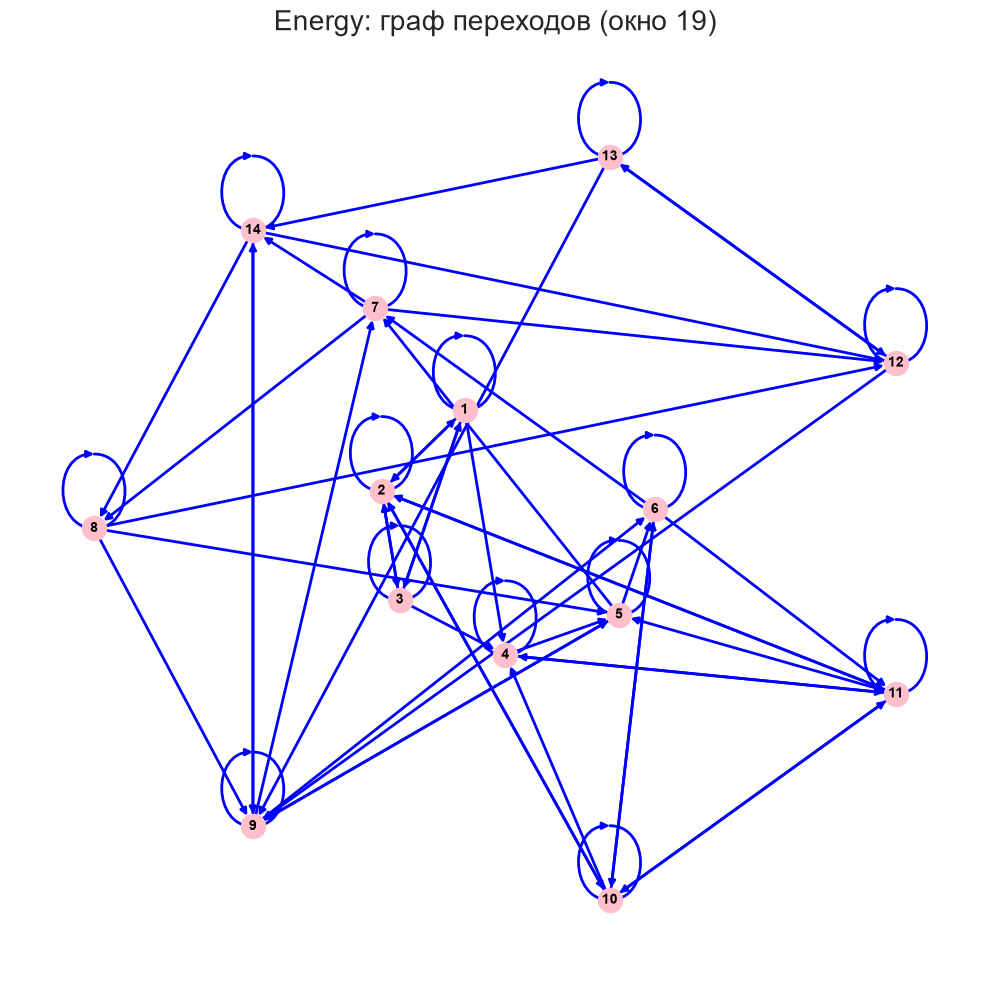

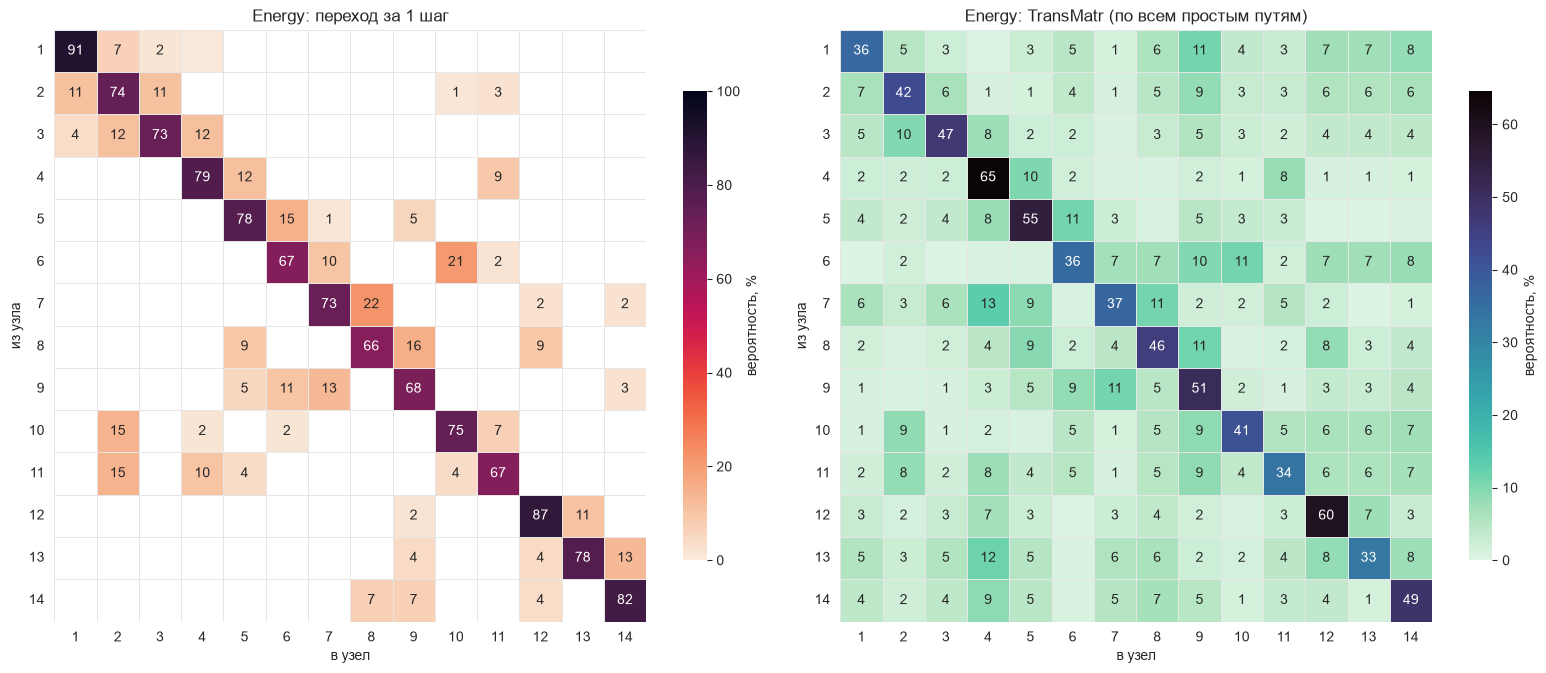

In [19]:
name = "Energy"
GR[name].DrawGraph(f"{name}: граф переходов (окно {2 * EMB[name] + 1})")
P1, Pall = show_transitions(name, GR[name])

14 узлов и 58 ребер, почти каждый узел связан с несколькими другими. Сезонная динамика с погодным шумом

На диагонали 66-91%, состояние держится несколько суток. Выходы разбросаны по несоседним узлам (2-22%). В TransMatr из любого узла достижим почти любой (1-12%): устойчивого цикла нет, переходы определяет погода

# Итоги

* Метро - самые низкие E и D2 из трех рядов (5 и 2.0), вне диапазона случайного блуждания, фазовая траектория - суточный цикл
* Энергия - по оценкам DimEmb неотличима от блуждания (E = 9, D2 = 5.6), вероятная причина - погода как внешний случайный фактор
* Apple - неотличим от случайного блуждания (E = 9, D2 = 4.3 в диапазоне эталонов), конечная D2 не означает детерминированной динамики
* t-SNE согласуется с этим. У метро предельный цикл (будни и выходные), у энергии сезонное облако, у Apple дрейф без возвратов
* Граф переходов это повторяет - у метро детерминированные цепочки, у энергии размытые переходы, у Apple переходы только между соседними уровнями цены.
* Окно LSTM длиной E или 2E+1 существенно лучше окна из работы 4 только на h = 1 у энергии (2.69 против 3.53%). У Apple окно E формально лучше, но в пределах случайности. Для метро оба окна хуже в 1.5–2.4 раза, потому что короче суточного периода